# IBM Quantum Vishnu Institute of Technology
## Qiskit Fall Fest 2026
### Challenge 1: Predict the Output

**Goal:** Predict the measurement outcome of three single-qubit circuits (A: one X gate, B: two X gates, C: one H gate), run each for **100 shots**, and compare the predictions with the actual results.

**Constraints satisfied:** exactly 1 qubit, initial state |0>, measurement included, only workshop gates (X, H), built and executed with Qiskit, 100 shots per experiment.

## Step 0: Setup

In [1]:
# Install dependencies (skip if already installed)
%pip install -q qiskit qiskit-aer matplotlib

Note: you may need to restart the kernel to use updated packages.


In [1]:
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
import matplotlib.pyplot as plt

SHOTS = 100
backend = AerSimulator()


def run_circuit(qc, shots=SHOTS):
    """Run a circuit and always return counts for both '0' and '1'."""
    compiled = transpile(qc, backend)
    result = backend.run(compiled, shots=shots).result()
    raw = result.get_counts()
    return {'0': raw.get('0', 0), '1': raw.get('1', 0)}

## Step 1: The Three Quantum Circuits

Each circuit uses 1 qubit (initialised in |0>) and 1 classical bit for the measurement.

In [2]:
# Circuit A: apply one X gate, then measure
qc_a = QuantumCircuit(1, 1, name='Circuit A')
qc_a.x(0)
qc_a.measure(0, 0)

# Circuit B: apply two X gates, then measure
qc_b = QuantumCircuit(1, 1, name='Circuit B')
qc_b.x(0)
qc_b.x(0)
qc_b.measure(0, 0)

# Circuit C: apply one H gate, then measure
qc_c = QuantumCircuit(1, 1, name='Circuit C')
qc_c.h(0)
qc_c.measure(0, 0)

for name, qc in [('Circuit A (X)', qc_a), ('Circuit B (X, X)', qc_b), ('Circuit C (H)', qc_c)]:
    print(name)
    print(qc.draw('text'))
    print()

Circuit A (X)
     ┌───┐┌─┐
  q: ┤ X ├┤M├
     └───┘└╥┘
c: 1/══════╩═
           0 

Circuit B (X, X)
     ┌───┐┌───┐┌─┐
  q: ┤ X ├┤ X ├┤M├
     └───┘└───┘└╥┘
c: 1/═══════════╩═
                0 

Circuit C (H)
     ┌───┐┌─┐
  q: ┤ H ├┤M├
     └───┘└╥┘
c: 1/══════╩═
           0 



## Step 2: Predictions (made before running)

| Circuit | Gates | State before measurement | Predicted outcome |
|---|---|---|---|
| **A** | X | X\|0> = \|1> | Always **1**: about **100 x '1'**, 0 x '0' |
| **B** | X, X | X(X\|0>) = \|0> | Always **0**: about **100 x '0'**, 0 x '1' |
| **C** | H | (\|0> + \|1>)/sqrt(2) | Random: **~50% '0' and ~50% '1'** (about 50/50 out of 100) |

**Reasoning**

- **One X gate:** the X gate is a bit-flip (quantum NOT). It maps |0> to |1>, so the measurement is always `1`.
- **Two X gates:** the X gate is its own inverse (X·X = I). The qubit flips to |1> and back to |0>, so the measurement is always `0`.
- **H gate:** the Hadamard gate creates an equal superposition. Each outcome has probability |1/sqrt(2)|^2 = 0.5.
- **Will Circuit C always give the same result?** **No.** A and B are deterministic, but C is probabilistic. Each shot is random, so the counts will be close to 50/50 but will differ slightly from run to run (for example 47/53 or 54/46) and will not be exactly 50/50 every time.

In [3]:
# Predictions stored as expected probabilities of measuring '0' and '1'
predictions = {
    'A': {'0': 0.0, '1': 1.0},   # X gate -> always 1
    'B': {'0': 1.0, '1': 0.0},   # X, X   -> always 0
    'C': {'0': 0.5, '1': 0.5},   # H gate -> 50/50
}
for k, v in predictions.items():
    print(f'Circuit {k} prediction: P(0) = {v["0"]:.2f}, P(1) = {v["1"]:.2f}')

Circuit A prediction: P(0) = 0.00, P(1) = 1.00
Circuit B prediction: P(0) = 1.00, P(1) = 0.00
Circuit C prediction: P(0) = 0.50, P(1) = 0.50


## Step 3: Execute each circuit for 100 shots

In [4]:
counts_a = run_circuit(qc_a)
counts_b = run_circuit(qc_b)
counts_c = run_circuit(qc_c)

print('Shots per circuit:', SHOTS)
print('Circuit A (X)    :', counts_a)
print('Circuit B (X, X) :', counts_b)
print('Circuit C (H)    :', counts_c)

Shots per circuit: 100
Circuit A (X)    : {'0': 0, '1': 100}
Circuit B (X, X) : {'0': 100, '1': 0}
Circuit C (H)    : {'0': 44, '1': 56}


## Step 4: Histograms

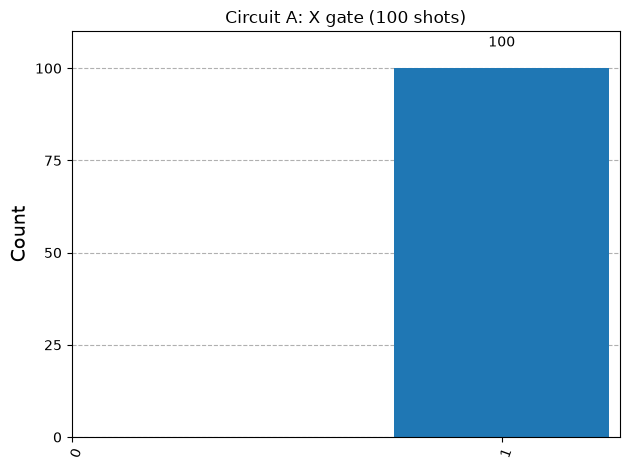

In [5]:
fig = plot_histogram(counts_a, title='Circuit A: X gate (100 shots)')
display(fig)

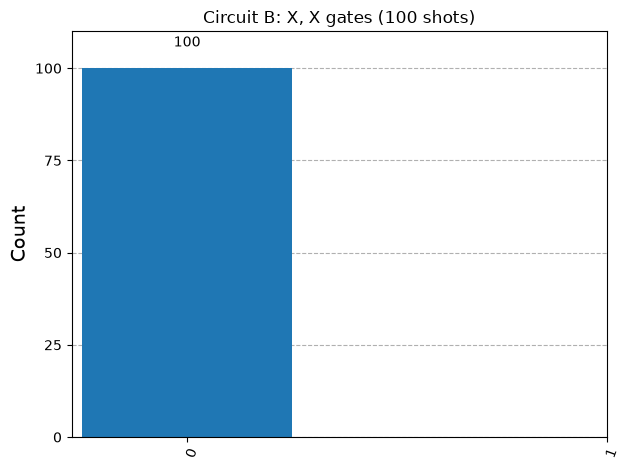

In [6]:
fig = plot_histogram(counts_b, title='Circuit B: X, X gates (100 shots)')
display(fig)

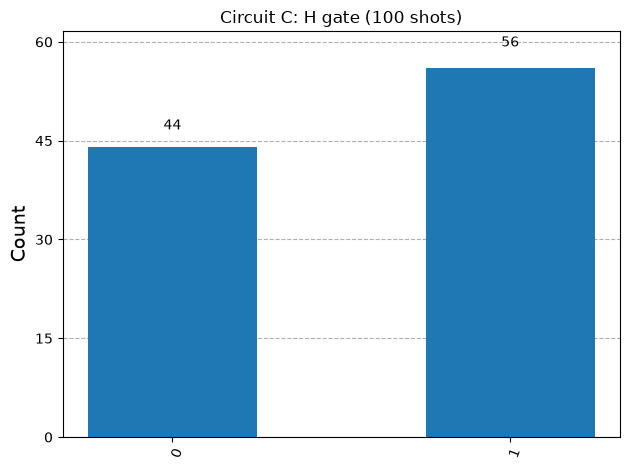

In [7]:
fig = plot_histogram(counts_c, title='Circuit C: H gate (100 shots)')
display(fig)

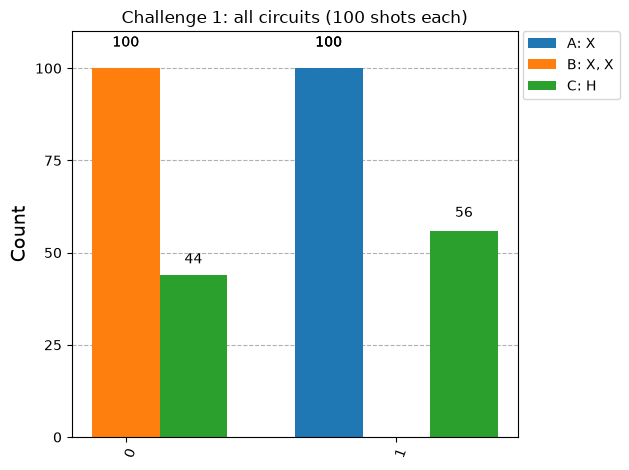

In [8]:
# Combined histogram of all three circuits
fig = plot_histogram(
    [counts_a, counts_b, counts_c],
    legend=['A: X', 'B: X, X', 'C: H'],
    title='Challenge 1: all circuits (100 shots each)',
)
display(fig)

## Step 5: Compare predictions with actual results

In [9]:
results = {'A': counts_a, 'B': counts_b, 'C': counts_c}

print(f'{"Circuit":<8}{"Predicted (0 / 1)":<22}{"Actual (0 / 1)":<18}Match?')
print('-' * 62)
for k in ['A', 'B', 'C']:
    pred0 = predictions[k]['0'] * SHOTS
    pred1 = predictions[k]['1'] * SHOTS
    act0, act1 = results[k]['0'], results[k]['1']
    if k in ('A', 'B'):
        ok = (act0 == pred0) and (act1 == pred1)          # must match exactly
    else:
        ok = abs(act0 - 50) <= 20 and abs(act1 - 50) <= 20  # roughly 50/50 (within statistical noise)
    print(f'{k:<8}{f"{pred0:.0f} / {pred1:.0f}":<22}{f"{act0} / {act1}":<18}{"YES" if ok else "NO"}')

Circuit Predicted (0 / 1)     Actual (0 / 1)    Match?
--------------------------------------------------------------
A       0 / 100               0 / 100           YES
B       100 / 0               100 / 0           YES
C       50 / 50               44 / 56           YES


### Short comparison of predictions vs. actual results

- **Circuit A (one X gate):** predicted `1` every time. The simulator gives `{'1': 100}`, an exact match. The X gate flips |0> to |1> deterministically.
- **Circuit B (two X gates):** predicted `0` every time. The simulator gives `{'0': 100}`, an exact match. Two X gates cancel each other (X·X = I), returning the qubit to |0>.
- **Circuit C (H gate):** predicted a random ~50/50 split. The result is a mix of `0` and `1` with each near 50 out of 100 (for example 48/52). The counts are not exactly 50/50 because of statistical (shot) noise, and they change each time the cell is run. Circuit C therefore does **not** always produce the same result, unlike A and B, because the H gate puts the qubit into an equal superposition and measurement collapses it randomly to 0 or 1.

**Conclusion:** the predictions agree with the measured results. Circuits A and B are deterministic, while Circuit C is probabilistic and approaches a 50/50 distribution as the number of shots increases.